In [5]:
from config import *
import Minimal_Model_1D as mm1D
import Minimal_Model_2D as mm2D
import Operators2D as O2d

In [71]:
####### First writing up a function to calculate wavefunctions #############

#t1 = time.time()

#print('t1 = ', t1)


DELTA = 0.165      # in meV
#MEFF_SC = 0.05     # Ge 
#MEFF_SM = 0.05     # proximitized Ge
MEFF_SC = 0.023     # proximitized InAs
MEFF_SM = 0.023     # InAs

LY = 100                            # in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC
print('confinement energy:', OMEGA , 'meV')


### Keeping it same so as to match with previous data 

MU_SM = 0.8 + OMEGA/2        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 0.8 + OMEGA/2        ## constant potential over reference level across all widths

K = 4

#AX = 0.25*math.sqrt(4*hbm/MEFF_SM/OMEGA)
#AY = 0.25*math.sqrt(4*hbm/MEFF_SM/OMEGA)

#print(AX, AY)

AX = 5
AY = 5 

NSC = 500
NSM = 60
M = 100
N = 2*NSC + NSM
PHI = 0.5*np.pi 

ALPHAT = 0.1                       ### low spin splitting to just break degeneracy

F2d = mm2D.twoD_Minimal_Model(N,NSM, NSC,M,AX ,AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

H2d = F2d.H_sys(PHI, so = 'li')

print(H2d.shape)

E2d, V2d = eigsh(H2d ,k=K,sigma=0, return_eigenvectors=True)

E2d = np.sort(E2d)

print(E2d)

print(np.unique(E2d))

confinement energy: 1.3263440267269595 meV
(424000, 424000)


In [26]:
V2d.shape

(424000, 4)

In [34]:
np.linalg.norm(V2d[:,2])

1.0000000000000002

In [36]:
A = np.array(V2d[:,2])

In [39]:
np.sum(np.abs(A)**4)

4.472772393870838e-05

In [27]:
WV1 = V2d[:,2].reshape((2,2,M*N))
WV2 = V2d[:,3].reshape((2,2,M*N))

In [28]:
print(WV1.shape)

(2, 2, 106000)


In [32]:
print(np.sum(WV1[:,:,:]**2))

(-0.009171326497884784-0.004934603146311412j)


Calculating variation of a correlation function wrt wavefunctions

In [47]:
def Correlation_2D(A, n, ax, ay, i, j, dl=1):

    """
        Returns correlation function between point labelled by i, j on a n X m lattice
        
        Args:
            A (float) : normalizing ocnstant for correlation function
            i, j (int) : index of two poins between which correlation function needs to be calculated
            dl (float) : decay length of correlation function 
        
    """

    x_dis = ((i%n) - (j%n))*ax   ## x distance between two points on lattice with index i,j labelled in graph way 

    y_dis = ((i//n) - (j//n))*ay   ## y distance between two points on lattice with index i,j labelled in graph way 

    return A**2 * math.exp(-abs(math.sqrt(x_dis**2 + y_dis**2))/dl)

In [48]:
Correlation_2D(1, 10 , 1, 1, 3, 4)

0.36787944117144233

Finding sigma 

In [1]:
def variance_of_correlation(WV, A, n, m, ax, ay, dl=1):

    """
        Returns <VV> for correlation 2D  
        
        Args:
            WV (array) : Array of dim (2X2XnXm, 1) representing wavefunction 
            A (float) : normalizing ocnstant for correlation function
            dl (float) : decay length of correlation function 
        
    """

    WVb = WV.reshape(2,2,m*n)

    sum = 0 

    for k in range(2):

        for l in range(2):

            for i in range(m*n):

                for j in range(m*n):

                    sum += sum + abs(WVb[k,l,i])**2*abs(WVb[k,l,j])**2*Correlation_2D(A, n, ax, ay, i, j, dl)

    return sum

In [6]:
def variance_of_equivalent_uncorrelated_disorder(WV, A, n, m, ax, ay, dl=1):

    """
        Returns equivalent <VV> or variance for uncorrelated disorder in 2D given correlated disorder magnitude A   
        
        Args:
            WV (array) : Array of dim (2X2XnXm, 1) representing wavefunction 
            A (float) : normalizing ocnstant for correlation function
            dl (float) : decay length of correlation function 
        
    """
 
    WVb = WV.reshape(2,2,m*n)           ### reshaping one D wavevector for ease of summing with the correlation function which relies on i,j being latice index

    var_corr = 0                        ### intializing variance of uncorrelated disorder

    for k in range(2):

        for l in range(2):

            for i in range(m*n):

                for j in range(m*n):

                    var_corr += abs(WVb[k,l,i])**2*abs(WVb[k,l,j])**2*Correlation_2D(A, n, ax, ay, i, j, dl) ### summing square of given wavefunction with correlation function to find corr_var

    var_uncorr = var_corr/np.sum(np.abs(WV)**4)      ### Finding corr var using uncorr var 

    return var_uncorr


Check it for ground state and first excited state of quantum well

In [ ]:
def QW_matrix(n, t, V, m):
    # Values for the main diagonal
    main_diag = 2 * t * np.ones(n)
    
    '''
    # Determine the start and end indices for the middle m entries
    if m > 0:
        start_index = (n - m) // 2
        end_index = start_index + m
        main_diag[start_index:end_index] += V  # Add V to the middle m entries
    '''
    
    # Values for the superdiagonal and subdiagonal
    off_diag = -t * np.ones(n - 1)
    
    # Create the sparse matrix
    # The '0' indicates the main diagonal, '1' indicates the superdiagonal, '-1' indicates the subdiagonal
    matrix = diags([main_diag, off_diag, off_diag], [0, 1, -1], format='csc')
    
    return matrix

# Example usage
n = 50  # Size of the matrix
t = hbm  # Value of t, a = 1 
print(t)
V = -10000  # Value to be added to the middle m entries
m = 10  # Number of middle entries to modify

H = QW_matrix(n, t, V, m)

print(H.toarray()[20:30,20:30])  # Convert to a dense array for display
print(H)


In [24]:
E, V = eigsh(H, k =3, sigma=0)

In [25]:
print(E)

[0.14464922 0.57804817 1.29855283]


In [23]:
print(hbm*np.pi**2/n**2)

0.15054064470074427


In [35]:
def QW_wf(n,i,a):

    return math.sqrt(2/(n-1)/a)*np.sin(i*np.pi*np.arange(n)/(n-1))

In [36]:
np.sin(1*np.pi*np.arange(n)/n)


array([0.        , 0.06279052, 0.12533323, 0.18738131, 0.24868989,
       0.30901699, 0.36812455, 0.42577929, 0.48175367, 0.53582679,
       0.58778525, 0.63742399, 0.68454711, 0.72896863, 0.77051324,
       0.80901699, 0.84432793, 0.87630668, 0.90482705, 0.92977649,
       0.95105652, 0.96858316, 0.98228725, 0.9921147 , 0.99802673,
       1.        , 0.99802673, 0.9921147 , 0.98228725, 0.96858316,
       0.95105652, 0.92977649, 0.90482705, 0.87630668, 0.84432793,
       0.80901699, 0.77051324, 0.72896863, 0.68454711, 0.63742399,
       0.58778525, 0.53582679, 0.48175367, 0.42577929, 0.36812455,
       0.30901699, 0.24868989, 0.18738131, 0.12533323, 0.06279052])

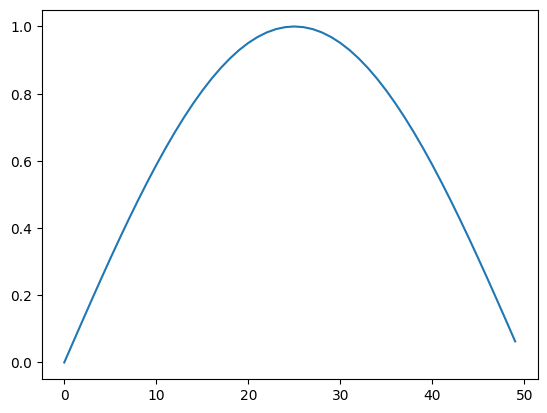

In [37]:
plt.plot(np.sin(1*np.pi*np.arange(n)/n))

In [33]:
print(QW_wf(10,1,1))

[0.         0.1381966  0.26286556 0.3618034  0.4253254  0.4472136
 0.4253254  0.3618034  0.26286556 0.1381966 ]


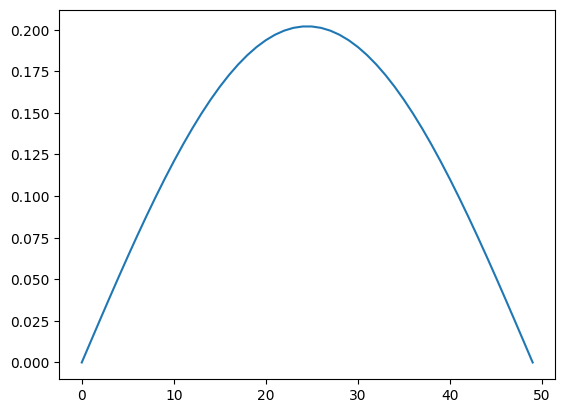

In [39]:
plt.plot(QW_wf(50,1,1))

In [40]:
np.sum(np.abs(QW_wf(50,1,1))**2)

0.9999999999999998

In [29]:
def Correlation_2D(A, n, ax, ay, i, j, dl=1):

    """
        Returns correlation function between point labelled by i, j on a n X m lattice
        
        Args:
            A (float) : normalizing ocnstant for correlation function
            i, j (int) : index of two poins between which correlation function needs to be calculated
            dl (float) : decay length of correlation function 
        
    """

    x_dis = ((i%n) - (j%n))*ax   ## x distance between two points on lattice with index i,j labelled in graph way 

    y_dis = ((i//n) - (j//n))*ay   ## y distance between two points on lattice with index i,j labelled in graph way 

    return A**2 * math.exp(-abs(math.sqrt(x_dis**2 + y_dis**2))/dl)

def variance_of_equivalent_uncorrelated_disorder(WV, A, n, m, ax, ay, dl=1):

    """
        Returns equivalent <VV> or variance for uncorrelated disorder in 2D given correlated disorder magnitude A   
        
        Args:
            WV (array) : Array of dim (2X2XnXm, 1) representing wavefunction 
            A (float) : normalizing ocnstant for correlation function
            dl (float) : decay length of correlation function 
        
    """
 
    WVb = WV.reshape(2,2,m*n)           ### reshaping one D wavevector for ease of summing with the correlation function which relies on i,j being latice index

    var_corr = 0                        ### intializing variance of uncorrelated disorder

    for k in range(2):

        for l in range(2):

            for i in range(m*n):

                for j in range(m*n):

                    var_corr += abs(WVb[k,l,i])**2*abs(WVb[k,l,j])**2*Correlation_2D(A, n, ax, ay, i, j, dl) ### summing square of given wavefunction with correlation function to find corr_var

    var_uncorr = var_corr/np.sum(np.abs(WV)**4)      ### Finding corr var using uncorr var 

    return var_uncorr, var_corr

def QW_wf(n,i,a):

    return math.sqrt(2/(n-1))*np.sin(i*np.pi*np.arange(n)/(n-1))

def QW_wf_2d(n, m, i, ax, ay):

    V = np.empty((m*n,1))

    for i in range(m):

        for j in range(n):

            V[i*m+j] = math.sqrt(2/(n-1))*math.sqrt(2/(m-1))*math.sin(j*math.pi/(n-1))*math.sin(i*math.pi/(m-1))

    return V 




In [30]:
WV = QW_wf_2d(50, 50, 1, 0.467, 0.9)

print(np.sum(np.abs(WV)**2))

0.9999999999999999


In [32]:
### one d qw m = 50, n= 50 

WV = np.tile(QW_wf(100, 1, 0.5), 4)/2   #### DIVIDING BY 2 TO MAKE NORM 1 

print(np.sum(np.abs(WV)**2))

print(np.sum(np.abs(QW_wf(100, 1, 0.5))**2))

print(variance_of_equivalent_uncorrelated_disorder(WV, 1, 100, 1, 0.5, 1, 1))

1.0000000000000004
1.0000000000000004
(4.061838091980401, 0.015385750348410618)


In [33]:
### one d qw m = 1, n= 50 

WV = np.tile(QW_wf(200, 1, 0.25), 4)/2   #### DIVIDING BY 2 TO MAKE NORM 1 

print(np.sum(np.abs(WV)**2))

print(np.sum(np.abs(QW_wf(200, 1, 0.25))**2))

print(variance_of_equivalent_uncorrelated_disorder(WV, 1, 200, 1, 0.25, 1, 1))

1.0
1.0
(7.999730794148633, 0.015074869586963505)


In [34]:
np.sum(np.abs(QW_wf(50, 1, 1))**2)

0.9999999999999998

In [38]:
## two d 

WV = np.tile(QW_wf_2d(20,20,1,1,1),4)/2   #### DIVIDING BY 2 TO MAKE NORM 1 

print(np.sum(np.abs(WV)**2))

print(np.sum(np.abs(QW_wf_2d(20,20,1,1,1) )**2))

print(variance_of_equivalent_uncorrelated_disorder(WV, 1, 20, 20, 1, 1, 1))

1.0000000000000002
1.0
(4.161453864678407, 0.006484259830696965)


In [ ]:
## two d 

WV = np.tile(QW_wf_2d(100,20,0.5,1),4)/2   #### DIVIDING BY 2 TO MAKE NORM 1 

print(np.sum(np.abs(WV)**2))

print(np.sum(np.abs(QW_wf_2d(100,20,0.5,1) )**2))

print(variance_of_equivalent_uncorrelated_disorder(WV, 1, 100, 20, 0.5, 1, 1))

In [14]:
50/400

0.125

In [39]:
WV = np.tile(np.ones(100),4)

print(variance_of_equivalent_uncorrelated_disorder(WV, 1, 10, 10, 1, 1, 1))


(5.0910345136709, 2036.4138054683601)


In [45]:
sum = 0 

for i in range(100):

    for j in range(100):

        sum += Correlation_2D(1,10,1,1,i,j,1)


print(sum*4)


2036.4138054684597
